### Instalação e Importação de Bibliotecas

In [ ]:
# Import das libs
import os
import json
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## Carregamento e Preparação dos dados

- Carregamento da base de Dados

- Engenharia de Recursos

In [4]:
print("Buscando dados históricos meteorológicos de Campinas/SP via Open-Meteo API...")


dados = "/monitoring_agent_output.json"

if not os.path.exists(dados):
    print(f"Por favor, faça o upload do arquivo '{dados}'...")
    uploaded = files.upload()
    dados = list(uploaded.keys())

# Leitura do DataFrame
if dados.endswith(".json"):
    df_raw = pd.read_json(dados)
else:
    df_raw = pd.read_csv(dados)

print(f"Registros totais no dataset: {len(df_raw)}")

# Filtragem: Seleciona apenas leituras válidas
df_validos = df_raw[df_raw['leitura_valida'] == True].copy()
df_validos['timestamp'] = pd.to_datetime(df_validos['data_hora'])
df_validos = df_validos.sort_values('timestamp').reset_index(drop=True)

# Converter níveis e taxas para metros
df_validos['nivel_atual_m'] = df_validos['nivel_atual_cm'] / 100.0
df_validos['taxa_variacao_m_h'] = (df_validos['taxa_subida_cm_min'] * 60.0) / 100.0

# Criando a Variável Alvo (Target y): Elevação real do nível após 60 minutos (1h)
df_validos['delta_nivel_futuro_1h'] = df_validos['nivel_atual_m'].shift(-1) - df_validos['nivel_atual_m']

# Remove linhas sem target futuro
df_treino = df_validos.dropna(subset=['delta_nivel_futuro_1h', 'taxa_variacao_m_h']).copy()

# Matrizes X (Taxa de variação e nível atual) e y (Elevação do nível)
X = df_treino[['taxa_variacao_m_h', 'nivel_atual_m']].values
y = df_treino['delta_nivel_futuro_1h'].values

print(f"Base de dados pronto para treino! {len(df_treino)} amostras válidas processadas.")

Buscando dados históricos meteorológicos de Campinas/SP via Open-Meteo API...
Registros totais no dataset: 8689
Base de dados pronto para treino! 8688 amostras válidas processadas.


### Estrutura da base de dados

Antes de avançarmos para as análises e modelagem, vamos verificar algumas informações basicas e estrutura geral do conjunto de dados.

In [5]:
# Informações gerais do DataFrame
print(f"Dimensões do DataFrame: {df_treino.shape[0]} linhas e {df_treino.shape[1]} colunas.\n")
df_treino.info()

# Exibindo as primeiras linhas
df_treino.head()

# Exibindo as últimas linhas
print("\n--- Últimas 5 linhas: ---")
df_treino.tail()

Dimensões do DataFrame: 8688 linhas e 13 colunas.

<class 'pandas.core.frame.DataFrame'>
Index: 8688 entries, 0 to 8687
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ponto_id               8688 non-null   object        
 1   data_hora              8688 non-null   object        
 2   tempo_decorrido_min    8688 non-null   int64         
 3   nivel_atual_cm         8688 non-null   int64         
 4   taxa_subida_cm_min     8688 non-null   float64       
 5   estado_ponto           8688 non-null   object        
 6   diagnostico_sensor     8688 non-null   object        
 7   leitura_valida         8688 non-null   bool          
 8   cota_critica_cm        8688 non-null   int64         
 9   timestamp              8688 non-null   datetime64[ns]
 10  nivel_atual_m          8688 non-null   float64       
 11  taxa_variacao_m_h      8688 non-null   float64       
 12  delta_nivel_futu

,ponto_id,data_hora,tempo_decorrido_min,nivel_atual_cm,taxa_subida_cm_min,estado_ponto,diagnostico_sensor,leitura_valida,cota_critica_cm,timestamp,nivel_atual_m,taxa_variacao_m_h,delta_nivel_futuro_1h
8683,PONTO_GUAIBA_01,2026-11-25 14:00:00,130440,89,0.0667,Normal,OK,True,380,2026-11-25 14:00:00,0.89,0.04002,0.01
8684,PONTO_GUAIBA_01,2026-11-25 14:15:00,130455,90,0.1000,Normal,OK,True,380,2026-11-25 14:15:00,0.90,0.06000,0.01
8685,PONTO_GUAIBA_01,2026-11-25 14:30:00,130470,91,0.0667,Normal,OK,True,380,2026-11-25 14:30:00,0.91,0.04002,0.00
8686,PONTO_GUAIBA_01,2026-11-25 14:45:00,130485,91,0.0333,Normal,OK,True,380,2026-11-25 14:45:00,0.91,0.01998,0.00
8687,PONTO_GUAIBA_01,2026-11-25 15:00:00,130500,91,0.0000,Normal,OK,True,380,2026-11-25 15:00:00,0.91,0.00000,0.00


### Resumo visual do DataFrame

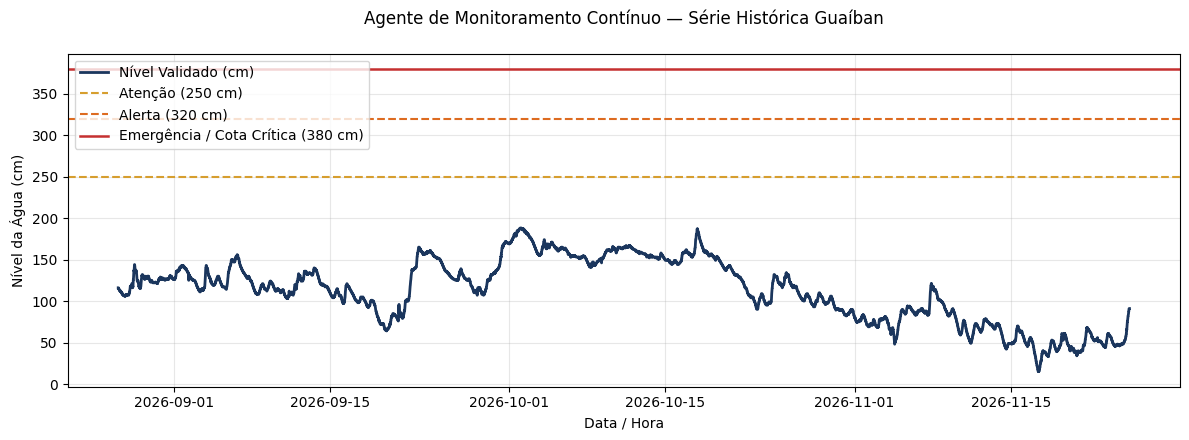

In [7]:
df_out = df_raw.copy()

# Definindo as constantes de limiares que são usadas no gráfico
LIMIAR_ATENCAO_CM = 250
LIMIAR_ALERTA_CM = 320
LIMIAR_EMERGENCIA_CM = 380


df_validos_vis = df_out[df_out["leitura_valida"]]
df_falhas_vis  = df_out[~df_out["leitura_valida"]]

plt.figure(figsize=(12, 4.5))
plt.plot(pd.to_datetime(df_validos_vis["data_hora"]), df_validos_vis["nivel_atual_cm"],
         color="#1B365D", linewidth=2, label="Nível Validado (cm)")

if not df_falhas_vis.empty:
    plt.scatter(pd.to_datetime(df_falhas_vis["data_hora"]), [0]*len(df_falhas_vis),
                color="#C53030", marker="x", s=70, zorder=5, label="Leitura Rejeitada (Falha)")

plt.axhline(LIMIAR_ATENCAO_CM, color="#D69E2E", linestyle="--", label="Atenção (250 cm)")
plt.axhline(LIMIAR_ALERTA_CM, color="#DD6B20", linestyle="--", label="Alerta (320 cm)")
plt.axhline(LIMIAR_EMERGENCIA_CM, color="#C53030", linestyle="-", linewidth=1.8, label="Emergência / Cota Crítica (380 cm)")

plt.title("Agente de Monitoramento Contínuo — Série Histórica Guaíban\n")
plt.xlabel("Data / Hora")
plt.ylabel("Nível da Água (cm)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Análise da Série Histórica
* **O que este gráfico representa:** Este gráfico exibe o **nível absoluto** da água do rio Guaíba em centímetros (variando entre $50\text{ cm}$ e mais de $150\text{ cm}$).
* **Comportamento observado:** Trata-se de uma linha contínua que representa a variação acumulada do nível da água ao longo de todo o período monitorado, permitindo visualizar tendências macro e a proximidade com as cotas físicas de Atenção, Alerta e Emergência.

### Organização do DataFrame: Separando Data e Hora

Para facilitar análises temporais específicas, desmembramos a coluna `data_hora` criando duas novas colunas independentes: `data` e `hora`.

In [8]:
# Garantindo que a coluna 'data_hora' está no formato datetime
df_treino['data_hora'] = pd.to_datetime(df_treino['data_hora'])

# Separa a coluna data_hora em 'data' e 'hora' no DataFrame df_treino
df_treino['data'] = df_treino['data_hora'].dt.date
df_treino['hora'] = df_treino['data_hora'].dt.time

# Reorganizando a ordem das colunas
colunas_reordenadas = ['data_hora', 'data', 'hora'] + [col for col in df_treino.columns if col not in ['data_hora', 'data', 'hora']]
df_clima = df_treino[colunas_reordenadas]

print("DataFrame df_clima criado e organizado com sucesso a partir de df_treino!")
df_clima.head()

DataFrame df_clima criado e organizado com sucesso a partir de df_treino!


,data_hora,data,hora,ponto_id,tempo_decorrido_min,nivel_atual_cm,taxa_subida_cm_min,estado_ponto,diagnostico_sensor,leitura_valida,cota_critica_cm,timestamp,nivel_atual_m,taxa_variacao_m_h,delta_nivel_futuro_1h
0,2026-08-27 00:00:00,2026-08-27,00:00:00,PONTO_GUAIBA_01,0,116,0.0000,Normal,OK,True,380,2026-08-27 00:00:00,1.16,0.00000,0.00
1,2026-08-27 00:15:00,2026-08-27,00:15:00,PONTO_GUAIBA_01,15,116,0.0000,Normal,OK,True,380,2026-08-27 00:15:00,1.16,0.00000,0.00
2,2026-08-27 00:30:00,2026-08-27,00:30:00,PONTO_GUAIBA_01,30,116,0.0000,Normal,OK,True,380,2026-08-27 00:30:00,1.16,0.00000,-0.01
3,2026-08-27 00:45:00,2026-08-27,00:45:00,PONTO_GUAIBA_01,45,115,-0.0333,Normal,OK,True,380,2026-08-27 00:45:00,1.15,-0.01998,0.00
4,2026-08-27 01:00:00,2026-08-27,01:00:00,PONTO_GUAIBA_01,60,115,-0.0333,Normal,OK,True,380,2026-08-27 01:00:00,1.15,-0.01998,0.00


In [9]:
# Removendo a coluna 'data_hora'
if 'data_hora' in df_clima.columns:
    df_clima = df_clima.drop(columns=['data_hora'])
    print("Coluna 'data_hora' removida com sucesso!")
else:
    print("A coluna 'data_hora' já havia sido removida.\n")

df_clima.head()

Coluna 'data_hora' removida com sucesso!


,data,hora,ponto_id,tempo_decorrido_min,nivel_atual_cm,taxa_subida_cm_min,estado_ponto,diagnostico_sensor,leitura_valida,cota_critica_cm,timestamp,nivel_atual_m,taxa_variacao_m_h,delta_nivel_futuro_1h
0,2026-08-27,00:00:00,PONTO_GUAIBA_01,0,116,0.0000,Normal,OK,True,380,2026-08-27 00:00:00,1.16,0.00000,0.00
1,2026-08-27,00:15:00,PONTO_GUAIBA_01,15,116,0.0000,Normal,OK,True,380,2026-08-27 00:15:00,1.16,0.00000,0.00
2,2026-08-27,00:30:00,PONTO_GUAIBA_01,30,116,0.0000,Normal,OK,True,380,2026-08-27 00:30:00,1.16,0.00000,-0.01
3,2026-08-27,00:45:00,PONTO_GUAIBA_01,45,115,-0.0333,Normal,OK,True,380,2026-08-27 00:45:00,1.15,-0.01998,0.00
4,2026-08-27,01:00:00,PONTO_GUAIBA_01,60,115,-0.0333,Normal,OK,True,380,2026-08-27 01:00:00,1.15,-0.01998,0.00


## Divisão dos Dados e Treinamento do Modelo

- Divisão em treino e teste

- Ajuste do Modelo Ridge


In [10]:
# Divisão temporal: 80% treino, 20% teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, shuffle=False
)

## Treinamento do modelo com busca automatica do melhor alpha (RidgeCV)

In [11]:
from sklearn.linear_model import RidgeCV

# Lista de valores de alpha a serem testados (de 0.001 a 1000.0 em escala logarítmica)
alphas_para_testar = np.logspace(-3, 3, 50)

# Inicialização do RidgeCV com Validação Cruzada com 5 folds
modelo = RidgeCV(
    alphas=alphas_para_testar,
    scoring='neg_root_mean_squared_error',
    cv=5
)

# Treinamento e escolha automática do melhor hiperparâmetro
modelo.fit(X_treino, y_treino)

print("Modelo RidgeCV treinado com sucesso!")
print("--------------------------------------------------")
print(f" ► Melhor Alpha encontrado: {modelo.alpha_:.4f}")
print(f" • Coeficiente Taxa de Variação (m/h): {modelo.coef_[0]:.5f}")
print(f" • Coeficiente Nível Atual (m):        {modelo.coef_[1]:.5f}")
print(f" • Intercepto (Viés):                  {modelo.intercept_:.5f}")
print("--------------------------------------------------")

Modelo RidgeCV treinado com sucesso!
--------------------------------------------------
 ► Melhor Alpha encontrado: 0.2812
 • Coeficiente Taxa de Variação (m/h): 0.04200
 • Coeficiente Nível Atual (m):        -0.00032
 • Intercepto (Viés):                  0.00037
--------------------------------------------------


## Avaliação de Desempenho e Métricas

- ### Avaliação de desempenho:

  - Métricas (MAE, RMSE, R²)
  - Curvas de desempenho

In [12]:
y_pred = modelo.predict(X_teste)

mae = mean_absolute_error(y_teste, y_pred)
rmse = np.sqrt(mean_squared_error(y_teste, y_pred))
r2 = r2_score(y_teste, y_pred)


print("Métricas:")
print("==================================================")
print(f" - MAE  (Erro Médio Absoluto):     {mae:.4f} metros")
print(f" - RMSE (Raiz do Erro Quadrático): {rmse:.4f} metros")
print(f" - R²   (Coeficiente Determinação): {r2:.4f}")
print("==================================================")

Métricas:
 - MAE  (Erro Médio Absoluto):     0.0052 metros
 - RMSE (Raiz do Erro Quadrático): 0.0078 metros
 - R²   (Coeficiente Determinação): 0.0624


### Análise de Resultados

#### Diagnóstico do Modelo
* **Desempenho Real (R² ≈ 0.0624):** O modelo obteve um coeficiente de determinação baixo ($R^2 \approx 6.2\%$). Isso indica que a relação linear simples baseada apenas na taxa de variação instantânea e no nível atual possui poder preditivo limitado para prever a variação do nível após 1 hora completa, sugerindo que o fenômeno é altamente dinâmico ou influenciado por outros fatores externos (como chuvas acumuladas ou escoamento da bacia).
* **Análise de Coeficientes:**
  * **Coeficiente da Taxa de Variação (m/h):** Ficou em `0.04200`. Ele possui um impacto positivo na previsão do delta futuro, como esperado.
  * **Coeficiente do Nível Atual (m):** Ficou em `-0.00032`, indicando uma influência quase nula do nível de partida absoluto na variação de curto prazo.
  * **Intercepto (Viés):** Ficou em `0.00037`, representando uma variação residual mínima próxima a zero.

### Curvas de desempenho

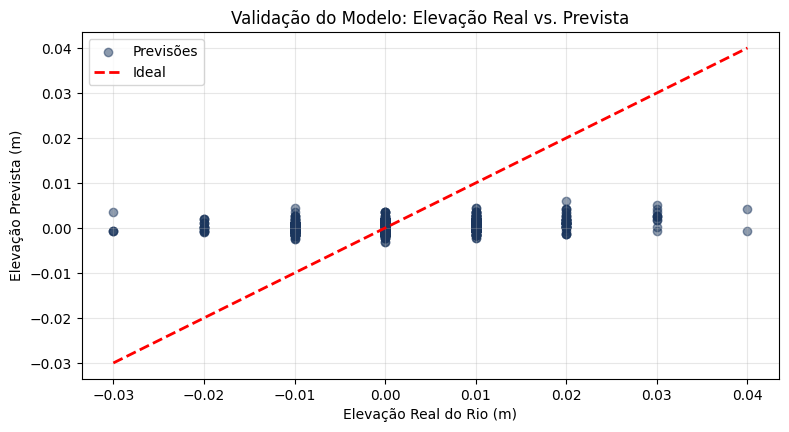

In [13]:
plt.figure(figsize=(9, 4.5))
plt.scatter(y_teste, y_pred, alpha=0.5, color='#1B365D', label='Previsões')
plt.plot([y_teste.min(), y_teste.max()], [y_teste.min(), y_teste.max()], 'r--', lw=2, label='Ideal')
plt.title('Validação do Modelo: Elevação Real vs. Prevista')
plt.xlabel('Elevação Real do Rio (m)')
plt.ylabel('Elevação Prevista (m)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Entendendo a Validação (Real vs. Previsto)

* **O que este gráfico representa:** Este gráfico avalia o desempenho do modelo na previsão do **delta de variação de curto prazo** (`delta_nivel_futuro_1h` em metros), que indica o quanto o rio vai subir ou descer após 1 hora.
* **Interpretação da Linha Vermelha (1:1):**
  * Representa o **cenário ideal** de previsão perfeita ($y_{\text{pred}} = y_{\text{teste}}$).
  * Os valores reais e previstos concentram-se em escalas muito pequenas (entre $-0.05\text{ m}$ e $+0.05\text{ m}$) porque representam variações de curto prazo de hora em hora, e não a altura total do rio.
  * O alinhamento vertical dos pontos ocorre devido à natureza discreta do sensor, que registra as leituras centímetro a centímetro.

### Salvando e Exportando o Modelo

In [14]:
NOME_MODELO = 'base_previsor.pkl'

# Salvando o modelo
joblib.dump(modelo, NOME_MODELO)
print(f"Modelo salvo com sucesso como '{NOME_MODELO}'.")
print("Extraindo o modelo...")
files.download(NOME_MODELO)

Modelo salvo com sucesso como 'base_previsor.pkl'.
Extraindo o modelo...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>